# Peak definition and fit window

**Question.** Does the Q0–Q20 peak understate a drug's real peak, and which peak definition and fit window best describe the first 3 years (Q0–Q12), the horizon the forecast uses?

**Why.** `share_of_peak` divides each quarter by the highest TRx in Q0–Q20 (decision 2026-10-22). `launch_eda` §3 finds 43% of full-window usable curves peak at Q20 and proposes keeping the Q0–Q20 peak, because the Q20 climb isn't explained by COVID enrollment growth. This notebook asks a different question: whether the Q0–Q20 peak is the real peak at all. `sdud_quarterly` has every quarter through 2026Q1, so curves can be followed past Q20.

Reads `data/processed/` only. Overlaps `launch_eda` §3 and §4.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# run from the repo root or from eda/
ROOT = Path.cwd() if (Path.cwd() / "pipeline").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT))  # for pipeline.common / pipeline.bass

# same chart style and categorical order as the other EDA notebooks (blue, orange, aqua; validated for CVD)
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8f8e89"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 9,
})
pd.set_option("display.width", 200)

In [2]:
from pipeline.common import qnum

features = pd.read_csv(PROCESSED / "analog_features.csv")
analogs = pd.read_csv(PROCESSED / "analogs.csv", dtype=str, keep_default_na=False)
curves = pd.read_csv(PROCESSED / "launch_curves.csv")
history = pd.read_csv(PROCESSED / "indication_history.csv")
sdud = pd.read_csv(PROCESSED / "sdud_quarterly.csv")
trx = sdud[sdud.metric == "trx"].assign(value=lambda d: pd.to_numeric(d.value, errors="coerce"))

# usable = end of the checks.md funnel
usable = set(features.loc[features.enough_data & ~features.late_launch & ~features.generic_entry_in_window, "analog_id"])

# same area definition as launch_eda, volume_vs_shape and pool_funnel: ATC 1, L split into oncology and immunology
# (classes are each analog's own since the pipeline's ATC fix, so Jakafi and Daliresp aren't "Dermatology")
ATC1 = {"A": "Alimentary & metabolism", "B": "Blood", "C": "Cardiovascular", "D": "Dermatology",
        "G": "GU & sex hormones", "H": "Systemic hormones", "J": "Anti-infectives", "M": "Musculoskeletal",
        "N": "Nervous system", "P": "Antiparasitic", "R": "Respiratory", "S": "Sensory organs", "V": "Various"}
broad = features.class_broad.fillna("")
features["area"] = broad.str[:1].map(ATC1).fillna("No ATC class")
features.loc[broad.str.startswith(("L01", "L02")), "area"] = "Oncology"
features.loc[broad.str.startswith(("L03", "L04")), "area"] = "Immunology"
print(f"{len(features)} analogs, {len(usable)} usable")

426 analogs, 250 usable


## 1. How far above the Q0–Q20 peak do curves go?

Every complete quarter since launch (the latest 2 SDUD quarters are provisional and left out), for usable analogs with a full Q0–Q20 window and at least one quarter after it. Ratio of the highest TRx after launch (all-time, and up to Q28) to the Q0–Q20 peak.

In [3]:
LAST_COMPLETE = sdud.period.map(qnum).max() - 2  # latest 2 SDUD quarters are provisional
launch = features.set_index("analog_id").launch_quarter.dropna().map(qnum)

# every complete quarter since launch, not just Q0-Q20
t = trx[trx.analog_id.isin(usable)].copy()
t["q"] = t.period.map(qnum) - t.analog_id.map(launch)
t = t[(t.q >= 0) & (t.period.map(qnum) <= LAST_COMPLETE)]
wide = t.pivot(index="analog_id", columns="q", values="value")
observed = t.groupby("analog_id").q.max()  # last complete quarter since launch
peak20 = wide.loc[:, 0:20].max(axis=1)

after = observed[observed > 20].index
s1 = pd.DataFrame({
    "quarters_after_q20": observed[after] - 20,
    "peak_at_q20": wide.loc[after, 20] >= peak20[after],
    "all_time_vs_q20_peak": wide.loc[after].max(axis=1) / peak20[after],
    "q28_vs_q20_peak": (wide.loc[after, 0:28].max(axis=1) / peak20[after]).where(observed[after] >= 28),
}).join(features.set_index("analog_id")[["area"]])
print(f"{len(s1)} usable analogs with a full Q0-Q20 window and later quarters "
      f"(median {s1.quarters_after_q20.median():.0f} quarters after Q20); {s1.peak_at_q20.sum()} peak at Q20")

def quartiles(s):
    return f"{s.quantile(.25):.2f} / {s.median():.2f} / {s.quantile(.75):.2f}"

s1.groupby("peak_at_q20").agg(
    analogs=("area", "size"),
    all_time_vs_q20_peak_q1_med_q3=("all_time_vs_q20_peak", quartiles),
    pct_5pct_higher_later=("all_time_vs_q20_peak", lambda s: round(100 * (s > 1.05).mean())),
    q28_vs_q20_peak_median=("q28_vs_q20_peak", "median"),
).round(2)

203 usable analogs with a full Q0-Q20 window and later quarters (median 18 quarters after Q20); 87 peak at Q20


,analogs,all_time_vs_q20_peak_q1_med_q3,pct_5pct_higher_later,q28_vs_q20_peak_median
peak_at_q20,,,,
False,116,1.00 / 1.00 / 1.20,35,1.00
True,87,1.18 / 1.44 / 2.07,95,1.35


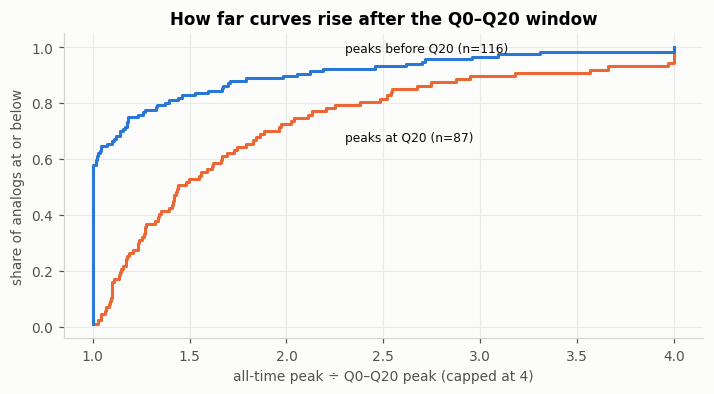

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for label, color, d in [("peaks at Q20", ORANGE, s1[s1.peak_at_q20]), ("peaks before Q20", BLUE, s1[~s1.peak_at_q20])]:
    x = np.sort(d.all_time_vs_q20_peak.clip(upper=4))
    y = np.arange(1, len(x) + 1) / len(x)
    ax.step(x, y, where="post", color=color)
    above = label == "peaks before Q20"  # its curve sits higher, so label it above, the other below
    ax.text(2.3, 0.97 if above else 0.70, f"{label} (n={len(x)})", va="bottom" if above else "top",
            color=INK, fontsize=8)
ax.set_xlabel("all-time peak ÷ Q0–Q20 peak (capped at 4)")
ax.set_ylabel("share of analogs at or below")
ax.set_title("How far curves rise after the Q0–Q20 window")
plt.show()

Is the climb after Q20 enrollment growth or label expansion? Among curves that peak at Q20: the Q20→Q28 rise when Q21–Q28 ends before COVID continuous coverage (2020Q2) vs when it overlaps it, and with vs without a possible label expansion after Q20 (`indication_history`; efficacy supplements over-count).

In [5]:
x = s1[s1.peak_at_q20].dropna(subset=["q28_vs_q20_peak"]).copy()
x["q21_q28"] = np.where(x.index.map(launch) + 28 < qnum("2020Q2"), "ends before COVID coverage", "overlaps COVID coverage")
expansions = set(history[(history.kind != "original") & (history.q_since_launch > 20)].analog_id)
x["expansion_after_q20"] = x.index.isin(expansions)
pd.concat({
    "by COVID overlap": x.groupby("q21_q28").q28_vs_q20_peak.agg(["size", "median"]),
    "by possible label expansion after Q20": x.groupby("expansion_after_q20").q28_vs_q20_peak.agg(["size", "median"]),
}).round(2)

size  median
by COVID overlap                      ends before COVID coverage    18    1.33
                                      overlaps COVID coverage       50    1.35
by possible label expansion after Q20 False                         13    1.23
                                      True                          55    1.39

## 2. Share of peak under three peak definitions

Same Q0–Q20 curves, divided by three peaks: the Q0–Q20 peak (current), the Q0–Q28 peak, and the all-time peak (complete quarters). Usable analogs with at least 28 complete quarters, so all three are defined on the same set.

In [6]:
long = observed[observed >= 28].index
w = wide.loc[long, 0:20]
peaks = {
    "Q0–Q20 peak (current)": wide.loc[long, 0:20].max(axis=1),
    "Q0–Q28 peak": wide.loc[long, 0:28].max(axis=1),
    "all-time peak": wide.loc[long].max(axis=1),
}
shares = {name: w.div(p, axis=0) for name, p in peaks.items()}
med = pd.DataFrame({name: s.median() for name, s in shares.items()})
print(f"{len(long)} usable analogs with >= 28 complete quarters")
med.loc[[4, 8, 12, 16, 20]].round(2).rename_axis("quarter since launch")

154 usable analogs with >= 28 complete quarters


,Q0–Q20 peak (current),Q0–Q28 peak,all-time peak
quarter since launch,,,
4,0.31,0.25,0.21
8,0.51,0.41,0.34
12,0.66,0.55,0.46
16,0.80,0.64,0.56
20,0.98,0.73,0.61


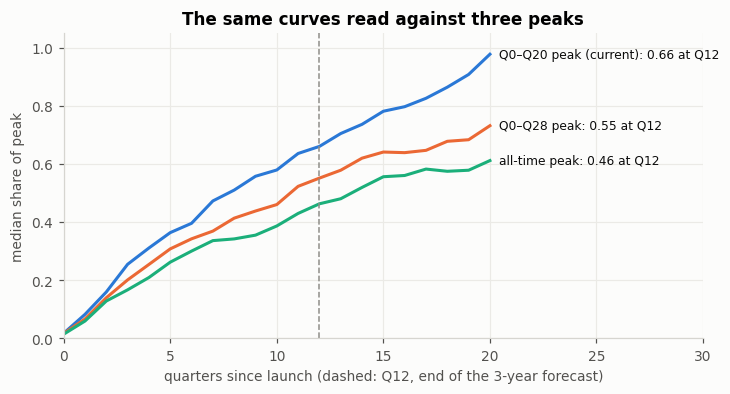

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for (name, color) in zip(med.columns, [BLUE, ORANGE, AQUA]):
    ax.plot(med.index, med[name], color=color)
    ax.annotate(f"{name}: {med.at[12, name]:.2f} at Q12", (20, med.at[20, name]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK, fontsize=8)
ax.axvline(12, color=GRAY, lw=1, ls="--")
ax.set_xlim(0, 30)
ax.set_ylim(0, 1.05)
ax.set_xlabel("quarters since launch (dashed: Q12, end of the 3-year forecast)")
ax.set_ylabel("median share of peak")
ax.set_title("The same curves read against three peaks")
plt.show()

In [8]:
# share of peak at Q12, by area (areas with >= 8 analogs in this set)
q12 = pd.DataFrame({name: s[12] for name, s in shares.items()}).join(features.set_index("analog_id")[["area"]])
counts = q12.area.value_counts()
q12[q12.area.isin(counts[counts >= 8].index)].groupby("area").median().round(2).assign(
    analogs=counts).sort_values("Q0–Q20 peak (current)")

,Q0–Q20 peak (current),Q0–Q28 peak,all-time peak,analogs
area,,,,
Immunology,0.57,0.56,0.43,14
Blood,0.62,0.56,0.56,11
Anti-infectives,0.65,0.53,0.53,13
Cardiovascular,0.66,0.48,0.35,8
Oncology,0.66,0.55,0.46,39
Nervous system,0.68,0.54,0.48,19
Alimentary & metabolism,0.69,0.60,0.33,25


## 3. Bass fits under each definition

Refit Bass with the pipeline's `pipeline.bass.fit` on Q0–Q20 for each normalization, same analogs as §2. Rescaling a curve by a constant only rescales m, so p and q should not change unless a bound binds (m's floor is 0.5).

In [9]:
from pipeline.bass import bass_cdf, fit, on_bound

rows = []
for a in long:
    y20 = w.loc[a]
    keep = y20.notna()
    tq = y20.index[keep].to_numpy(float) + 1
    for name, p in peaks.items():
        y = (y20[keep] / p[a]).to_numpy(float)
        bp, bq, bm, r2 = fit(tq, y)
        rows.append({"analog_id": a, "peak": name, "p": bp, "q": bq, "m": bm, "r2": r2,
                     "on_bound": on_bound((bp, bq, bm)), "m_at_cap": bm >= 4.99,
                     "m_at_floor": bm <= 0.505})
refit = pd.DataFrame(rows)
qq = refit.pivot(index="analog_id", columns="peak", values="q")
print(f"q unchanged (|diff| < 0.001) between Q0-Q20 and all-time normalization: "
      f"{100 * ((qq['Q0–Q20 peak (current)'] - qq['all-time peak']).abs() < 0.001).mean():.0f}% of analogs")
refit.groupby("peak", sort=False).agg(
    p=("p", "median"), q=("q", "median"), m=("m", "median"), r2=("r2", "median"),
    on_bound=("on_bound", "sum"), m_at_cap=("m_at_cap", "sum"), m_at_floor=("m_at_floor", "sum"),
).round(3)

q unchanged (|diff| < 0.001) between Q0-Q20 and all-time normalization: 78% of analogs


,p,q,m,r2,on_bound,m_at_cap,m_at_floor
peak,,,,,,,
Q0–Q20 peak (current),0.029,0.192,1.045,0.960,36,20,5
Q0–Q28 peak,0.029,0.186,0.865,0.960,39,19,10
all-time peak,0.028,0.159,0.799,0.961,56,19,29


## 4. Which fit window best describes Q0–Q12?

Fit Bass on Q0–Q12, Q0–Q20 and Q0–Q28 (share of the Q0–Q28 peak, so all three windows see values ≤ 1), same analogs. For each: error on Q0–Q12 (what the forecast uses), error on Q13–Q20 (does the shape hold past the window), share of fits with a parameter on a bound, and how much q moves between windows. Error = RMSE in share-of-peak units.

In [10]:
s28 = wide.loc[long, 0:28].div(peaks["Q0–Q28 peak"], axis=0)

def rmse(y, params, lo, hi):
    seg = y.loc[lo:hi].dropna()
    return np.sqrt(((seg.to_numpy() - bass_cdf(seg.index.to_numpy(float) + 1, *params)) ** 2).mean())

rows = []
for a in long:
    y = s28.loc[a]
    for window in (12, 20, 28):
        seg = y.loc[0:window].dropna()
        bp, bq, bm, _ = fit(seg.index.to_numpy(float) + 1, seg.to_numpy(float))
        rows.append({"analog_id": a, "window": f"Q0–Q{window}", "p": bp, "q": bq, "m": bm,
                     "on_bound": on_bound((bp, bq, bm)),
                     "rmse_q0_q12": rmse(y, (bp, bq, bm), 0, 12), "rmse_q13_q20": rmse(y, (bp, bq, bm), 13, 20)})
windows = pd.DataFrame(rows)
qw = windows.pivot(index="analog_id", columns="window", values="q")
print(f"q moves by > 50% between the Q0-Q12 and Q0-Q20 fits for "
      f"{100 * ((qw['Q0–Q12'] - qw['Q0–Q20']).abs() / qw['Q0–Q20'].clip(lower=0.01) > 0.5).mean():.0f}% of analogs")
windows.groupby("window").agg(
    p=("p", "median"), q=("q", "median"), q_iqr=("q", lambda s: f"{s.quantile(.25):.2f}–{s.quantile(.75):.2f}"),
    pct_on_bound=("on_bound", lambda s: round(100 * s.mean())),
    rmse_q0_q12=("rmse_q0_q12", "median"), rmse_q13_q20=("rmse_q13_q20", "median"),
).round(3)

q moves by > 50% between the Q0-Q12 and Q0-Q20 fits for 53% of analogs


,p,q,q_iqr,pct_on_bound,rmse_q0_q12,rmse_q13_q20
window,,,,,,
Q0–Q12,0.034,0.260,0.08–0.50,41,0.029,0.146
Q0–Q20,0.029,0.186,0.05–0.39,25,0.042,0.043
Q0–Q28,0.023,0.178,0.06–0.56,24,0.049,0.053


## Takeaways

- **The Q0–Q20 peak is often not the peak.** Of 203 usable analogs followed past Q20, 87 peak at Q20, and 95% of those go more than 5% higher later: median 1.44× the Q0–Q20 peak (quartiles 1.18–2.07). Curves that peak before Q20 mostly stay there (median 1.00).
- **It isn't COVID.** Among curves that peak at Q20, the Q20→Q28 rise is the same whether Q21–Q28 ends before COVID continuous coverage (1.33×, n = 18) or overlaps it (1.35×, n = 50). It is larger with a possible label expansion after Q20 (1.39× vs 1.23×), but still clearly above 1 without one. This is consistent with `launch_eda` §3 (no COVID signal), but the conclusion differs: the Q0–Q20 peak understates where these launches go.
- **The peak definition changes the 3-year read a lot.** Median share of peak at Q12 is 0.66 against the Q0–Q20 peak, 0.55 against the Q0–Q28 peak and 0.46 against the all-time peak (154 analogs with ≥ 28 quarters). "Reaches two-thirds of peak in 3 years" becomes "about half".
- **It doesn't change the Bass shape.** Rescaling only moves m: q is unchanged for 78% of analogs, and the rest differ because m hits its 0.5 floor more often (5 → 29 fits under the all-time peak). p and q describe the shape; the peak definition decides how that shape maps to the ceiling.
- **The fit window is what moves p and q.** Fitting only Q0–Q12 matches the first 3 years best (RMSE 0.029 vs 0.042 for Q0–Q20), but 41% of those fits sit on a bound (vs 25%), q moves by > 50% for half the analogs, and the curve misses Q13–Q20 badly (RMSE 0.146 vs 0.043). Q0–Q20 is the better compromise; Q0–Q28 adds little.

**Suggests:** keep fitting Bass on Q0–Q20, but don't treat the Q0–Q20 peak as the ceiling: report share of the peak over a fixed horizon longer than the fit window (e.g. Q0–Q28) when reading uptake at Q12, not the all-time peak, and lower m's floor if the normalization changes. The all-time peak isn't a fair denominator: its horizon depends on launch year (12 years of data for a 2012 launch, 6 for a 2019 one), it is still rising for drugs at their highest today, and it mixes in later indications.